<a href="https://colab.research.google.com/github/EmptyRain75/mnist-ai-classifier/blob/main/experiments/01_softmax_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Softmax Regression Experiments

We will add experiments one at a time: **baseline timing → learning rate → batch size → training duration**.

Keep each study short, change one setting at a time, and compare validation results. Reserve the test set for the final selected configuration.

Try to keep it short, under 2 hours.

## 1. Baseline and Timing

**Question:** How long does one five-epoch run take on this runtime?

| Setting | Value |
|---|---|
| Model | Flatten → Linear(784, 10), 7,850 parameters |
| Input scaling | Pixels in [0, 1] |
| Train / validation | 50,000 / 10,000, seed 42 |
| Optimizer | SGD, no momentum or weight decay |
| Learning rate | 0.1 |
| Batch size | 32 |
| Epochs | 5 |

This preserves the existing PyTorch Softmax configuration. Its split and initialization differ from the NumPy baseline, so we compare experiments within this notebook.

Timing includes training and per-epoch validation, excludes downloading and setup. A 15-minute guard stops this initial run if the runtime is unusually slow. The notebook also tracks a cumulative two-hour run budget, with a one-minute stopping margin. Checks happen between batches; they cannot interrupt a stalled operation.

In Colab, select a GPU if available, then run the cells below in order.

In [1]:
import time
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(device))

# Run this setup cell once. Rerunning it resets the time ledger.
TOTAL_BUDGET_SECONDS = 2 * 60 * 60
STOP_MARGIN_SECONDS = 60
used_run_seconds = 0.0
results = []


Device: cuda
GPU: Tesla T4


In [2]:
full_train = datasets.MNIST(
    root="./data", train=True, download=True,
    transform=transforms.ToTensor(),
)
train_dataset, val_dataset = random_split(
    full_train, [50000, 10000],
    generator=torch.Generator().manual_seed(SEED),
)

val_loader = DataLoader(val_dataset, batch_size=512, shuffle=False)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
# The test set is deliberately left until final model selection.


100%|██████████| 9.91M/9.91M [00:00<00:00, 20.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 505kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.62MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.57MB/s]

Training images: 50000
Validation images: 10000


### Shared Run Function

Every run starts with fresh parameters and the same seeded training shuffle. Record sample-weighted losses and validation accuracy. Keep this function for the next studies.

In [3]:
class SoftmaxRegression(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(784, 10)

    def forward(self, images):
        return self.linear(images.flatten(start_dim=1))


def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize(device)


def run_experiment(name, lr=0.1, batch_size=32, epochs=5,
                   max_run_seconds=15 * 60):
    global used_run_seconds
    available = TOTAL_BUDGET_SECONDS - STOP_MARGIN_SECONDS - used_run_seconds
    if available <= 0:
        raise RuntimeError("Notebook time budget exhausted.")

    torch.manual_seed(SEED)
    model = SoftmaxRegression().to(device)
    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    history = {"train_loss": [], "val_loss": [], "val_accuracy": [],
               "epoch_seconds": []}

    synchronize()
    started = time.perf_counter()
    deadline = started + min(max_run_seconds, available)
    status = "interrupted"

    def check_time():
        if time.perf_counter() >= deadline:
            raise TimeoutError("Time guard reached; stop and report elapsed time.")

    try:
        for epoch in range(epochs):
            epoch_started = time.perf_counter()
            model.train()
            train_loss = 0.0
            for images, labels in train_loader:
                check_time()
                images, labels = images.to(device), labels.to(device)
                optimizer.zero_grad()
                loss = criterion(model(images), labels)
                if not torch.isfinite(loss).item():
                    raise RuntimeError("Non-finite loss: this configuration diverged.")
                loss.backward()
                optimizer.step()
                train_loss += loss.item() * labels.size(0)

            model.eval()
            val_loss, correct = 0.0, 0
            with torch.no_grad():
                for images, labels in val_loader:
                    check_time()
                    images, labels = images.to(device), labels.to(device)
                    logits = model(images)
                    val_loss += criterion(logits, labels).item() * labels.size(0)
                    correct += (logits.argmax(1) == labels).sum().item()

            synchronize()
            epoch_seconds = time.perf_counter() - epoch_started
            history["train_loss"].append(train_loss / len(train_dataset))
            history["val_loss"].append(val_loss / len(val_dataset))
            history["val_accuracy"].append(correct / len(val_dataset))
            history["epoch_seconds"].append(epoch_seconds)
            print(
                f"Epoch {epoch + 1}/{epochs} | "
                f"Train loss {history['train_loss'][-1]:.4f} | "
                f"Val loss {history['val_loss'][-1]:.4f} | "
                f"Val acc {history['val_accuracy'][-1]:.2%} | "
                f"{epoch_seconds:.1f} s"
            )
        status = "completed"
    finally:
        synchronize()
        elapsed = time.perf_counter() - started
        used_run_seconds += elapsed
        results.append({
            "name": name, "lr": lr, "batch_size": batch_size,
            "requested_epochs": epochs, "completed_epochs": len(history["train_loss"]),
            "seconds": elapsed, "status": status, "history": history,
        })
        print(f"Run time (training + validation): {elapsed:.1f} s")
        print(f"Cumulative run time: {used_run_seconds / 60:.1f} / 120 min")

    return model, results[-1]


### Run the Baseline

Run this cell once. Rerunning it trains a fresh model and adds another run to the time ledger.

In [4]:
baseline_model, baseline = run_experiment(
    name="baseline", lr=0.1, batch_size=32, epochs=5,
)

print(f"Parameters: {sum(p.numel() for p in baseline_model.parameters()):,}")
print(f"Mean time per epoch: {baseline['seconds'] / 5:.1f} s")
print(f"Final validation accuracy: {baseline['history']['val_accuracy'][-1]:.2%}")


Epoch 1/5 | Train loss 0.4284 | Val loss 0.3421 | Val acc 90.46% | 8.6 s
Epoch 2/5 | Train loss 0.3180 | Val loss 0.3228 | Val acc 90.75% | 8.3 s
Epoch 3/5 | Train loss 0.2995 | Val loss 0.3111 | Val acc 91.20% | 8.0 s
Epoch 4/5 | Train loss 0.2890 | Val loss 0.3068 | Val acc 91.21% | 8.2 s
Epoch 5/5 | Train loss 0.2826 | Val loss 0.3042 | Val acc 91.50% | 8.4 s
Run time (training + validation): 41.4 s
Cumulative run time: 0.7 / 120 min
Parameters: 7,850
Mean time per epoch: 8.3 s
Final validation accuracy: 91.50%


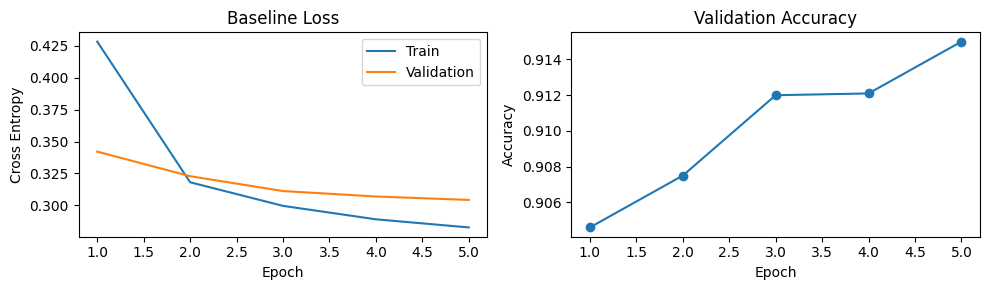

In [5]:
history = baseline["history"]
epoch_numbers = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(epoch_numbers, history["train_loss"], label="Train")
axes[0].plot(epoch_numbers, history["val_loss"], label="Validation")
axes[0].set(xlabel="Epoch", ylabel="Cross Entropy", title="Baseline Loss")
axes[0].legend()
axes[1].plot(epoch_numbers, history["val_accuracy"], marker="o")
axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Validation Accuracy")
plt.tight_layout()
plt.show()


## 2. Learning Rate

**Question:** How does learning rate affect convergence and validation performance?

Compare 0.01, 0.03, 0.1, and 0.3. Reuse the existing 0.1 baseline.

Keep batch size 32, five epochs, initialization, and data split fixed.
Compare final validation loss and accuracy; leave the test set untouched.

In [6]:
lr_results = [baseline]

for lr in [0.01, 0.03, 0.3]:
    print(f"\nLearning rate: {lr}")
    _, result = run_experiment(
        name=f"learning_rate_{lr}",
        lr=lr,
        batch_size=32,
        epochs=5,
    )
    lr_results.append(result)

print(f"\n{'LR':>8} {'Val loss':>12} {'Val acc':>12} {'Time (s)':>12}")

for result in sorted(lr_results, key=lambda r: r["lr"]):
    history = result["history"]
    print(
        f"{result['lr']:>8.2f}"
        f"{history['val_loss'][-1]:>12.4f}"
        f"{history['val_accuracy'][-1]:>12.2%}"
        f"{result['seconds']:>12.1f}"
    )

print(f"\nCumulative run time: {used_run_seconds / 60:.1f} / 120 min")


Learning rate: 0.01
Epoch 1/5 | Train loss 0.8148 | Val loss 0.5328 | Val acc 87.13% | 8.6 s
Epoch 2/5 | Train loss 0.4748 | Val loss 0.4444 | Val acc 88.32% | 8.4 s
Epoch 3/5 | Train loss 0.4167 | Val loss 0.4064 | Val acc 89.11% | 8.5 s
Epoch 4/5 | Train loss 0.3876 | Val loss 0.3850 | Val acc 89.47% | 7.9 s
Epoch 5/5 | Train loss 0.3694 | Val loss 0.3709 | Val acc 89.87% | 8.3 s
Run time (training + validation): 41.6 s
Cumulative run time: 1.4 / 120 min

Learning rate: 0.03
Epoch 1/5 | Train loss 0.5722 | Val loss 0.4075 | Val acc 89.07% | 8.1 s
Epoch 2/5 | Train loss 0.3737 | Val loss 0.3632 | Val acc 90.01% | 7.9 s
Epoch 3/5 | Train loss 0.3417 | Val loss 0.3428 | Val acc 90.45% | 8.4 s
Epoch 4/5 | Train loss 0.3247 | Val loss 0.3312 | Val acc 90.56% | 8.1 s
Epoch 5/5 | Train loss 0.3140 | Val loss 0.3238 | Val acc 90.93% | 8.0 s
Run time (training + validation): 40.5 s
Cumulative run time: 2.1 / 120 min

Learning rate: 0.3
Epoch 1/5 | Train loss 0.3747 | Val loss 0.3297 | Val ac

### Learning-Rate Findings

Learning rate 0.1 achieved the best final validation results:
loss 0.3042 and accuracy 91.50%.

Smaller rates improved more slowly. At 0.3, validation loss
increased after epoch 3 despite decreasing training loss.

Use 0.1 for the next study. These findings apply to this
five-epoch configuration.

## 3. Batch Size

**Question:** How does batch size affect runtime and validation performance?

Compare 32, 128, and 512; reuse the batch-size-32 baseline.
Keep learning rate 0.1 and five epochs fixed.

Larger batches perform fewer optimizer updates per epoch.
This compares equal passes through the data, rather than
equal numbers of parameter updates.

In [8]:
batch_results = [baseline]

for batch_size in [128, 512]:
    print(f"\nBatch size: {batch_size}")
    _, result = run_experiment(
        name=f"batch_size_{batch_size}",
        lr=0.1,
        batch_size=batch_size,
        epochs=5,
    )
    batch_results.append(result)

print(
    f"\n{'Batch':>8} {'Updates':>10}"
    f"{'Val loss':>12} {'Val acc':>12} {'Time (s)':>12}"
)

for result in sorted(batch_results, key=lambda r: r["batch_size"]):
    history = result["history"]
    updates = (
        (len(train_dataset) + result["batch_size"] - 1)
        // result["batch_size"]
    ) * result["completed_epochs"]

    print(
        f"{result['batch_size']:>8}"
        f"{updates:>10}"
        f"{history['val_loss'][-1]:>12.4f}"
        f"{history['val_accuracy'][-1]:>12.2%}"
        f"{result['seconds']:>12.1f}"
    )

print(f"\nCumulative run time: {used_run_seconds / 60:.1f} / 120 min")


Batch size: 128
Epoch 1/5 | Train loss 0.6047 | Val loss 0.4228 | Val acc 88.93% | 7.0 s
Epoch 2/5 | Train loss 0.3862 | Val loss 0.3751 | Val acc 89.56% | 6.4 s
Epoch 3/5 | Train loss 0.3512 | Val loss 0.3508 | Val acc 90.34% | 7.0 s
Epoch 4/5 | Train loss 0.3328 | Val loss 0.3376 | Val acc 90.52% | 6.7 s
Epoch 5/5 | Train loss 0.3211 | Val loss 0.3295 | Val acc 90.71% | 7.0 s
Run time (training + validation): 34.1 s
Cumulative run time: 4.3 / 120 min

Batch size: 512
Epoch 1/5 | Train loss 0.9666 | Val loss 0.6189 | Val acc 85.91% | 6.0 s
Epoch 2/5 | Train loss 0.5433 | Val loss 0.4995 | Val acc 87.47% | 6.8 s
Epoch 3/5 | Train loss 0.4660 | Val loss 0.4494 | Val acc 88.31% | 6.0 s
Epoch 4/5 | Train loss 0.4280 | Val loss 0.4212 | Val acc 88.96% | 6.7 s
Epoch 5/5 | Train loss 0.4045 | Val loss 0.4026 | Val acc 89.15% | 6.0 s
Run time (training + validation): 31.4 s
Cumulative run time: 4.9 / 120 min

   Batch    Updates    Val loss      Val acc     Time (s)
      32      7815      0

### Batch-Size Findings

At learning rate 0.1 and five epochs, batch size 32 achieved
the lowest validation loss and highest validation accuracy.

Larger batches ran slightly faster but performed fewer updates:
7,815 for batch 32 versus 490 for batch 512.

These results do not establish that larger batches are inherently
worse; their learning rate and training duration may need adjustment.

## 4. Training Duration

**Question:** Does longer training improve validation performance?

Train one fresh model for 20 epochs and inspect epochs 5, 10,
and 20. Earlier checkpoints come from the same run, avoiding
separate training runs for each duration.

Keep learning rate 0.1 and batch size 32 fixed.
Watch whether validation loss improves or begins increasing.

In [9]:
duration_model, duration_result = run_experiment(
    name="training_duration",
    lr=0.1,
    batch_size=32,
    epochs=20,
)

h = duration_result["history"]

print(
    f"\n{'Epochs':>8} {'Train loss':>12}"
    f"{'Val loss':>12} {'Val acc':>12} {'Time (s)':>12}"
)

for epochs in [5, 10, 20]:
    i = epochs - 1
    print(
        f"{epochs:>8}"
        f"{h['train_loss'][i]:>12.4f}"
        f"{h['val_loss'][i]:>12.4f}"
        f"{h['val_accuracy'][i]:>12.2%}"
        f"{sum(h['epoch_seconds'][:epochs]):>12.1f}"
    )

best_epoch = min(
    range(len(h["val_loss"])),
    key=lambda i: h["val_loss"][i],
) + 1

print(f"\nLowest validation loss occurred at epoch {best_epoch}.")
print("The returned model contains the final epoch's parameters.")
print(f"Cumulative run time: {used_run_seconds / 60:.1f} / 120 min")

Epoch 1/20 | Train loss 0.4284 | Val loss 0.3421 | Val acc 90.46% | 8.5 s
Epoch 2/20 | Train loss 0.3180 | Val loss 0.3228 | Val acc 90.75% | 8.4 s
Epoch 3/20 | Train loss 0.2995 | Val loss 0.3111 | Val acc 91.20% | 8.2 s
Epoch 4/20 | Train loss 0.2890 | Val loss 0.3068 | Val acc 91.21% | 8.6 s
Epoch 5/20 | Train loss 0.2826 | Val loss 0.3042 | Val acc 91.50% | 8.6 s
Epoch 6/20 | Train loss 0.2774 | Val loss 0.3034 | Val acc 91.50% | 8.0 s
Epoch 7/20 | Train loss 0.2735 | Val loss 0.2983 | Val acc 91.69% | 8.6 s
Epoch 8/20 | Train loss 0.2703 | Val loss 0.2984 | Val acc 91.71% | 8.6 s
Epoch 9/20 | Train loss 0.2677 | Val loss 0.3017 | Val acc 91.81% | 8.1 s
Epoch 10/20 | Train loss 0.2652 | Val loss 0.3018 | Val acc 91.68% | 8.5 s
Epoch 11/20 | Train loss 0.2633 | Val loss 0.2954 | Val acc 91.67% | 8.5 s
Epoch 12/20 | Train loss 0.2615 | Val loss 0.2964 | Val acc 91.69% | 7.9 s
Epoch 13/20 | Train loss 0.2599 | Val loss 0.2961 | Val acc 91.74% | 8.4 s
Epoch 14/20 | Train loss 0.2586 | 

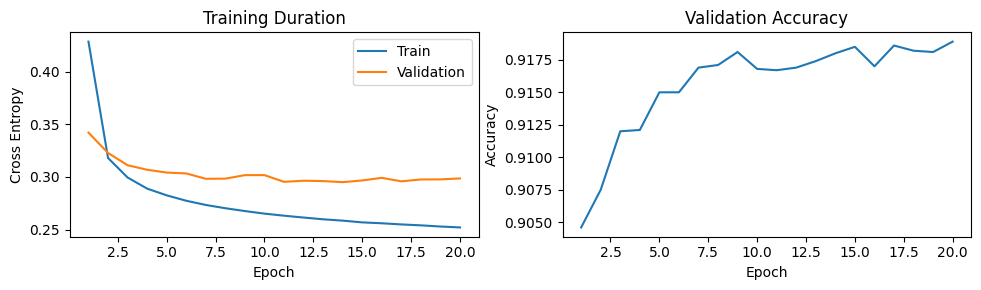

In [10]:
epochs = range(1, len(h["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

axes[0].plot(epochs, h["train_loss"], label="Train")
axes[0].plot(epochs, h["val_loss"], label="Validation")
axes[0].set(xlabel="Epoch", ylabel="Cross Entropy", title="Training Duration")
axes[0].legend()

axes[1].plot(epochs, h["val_accuracy"])
axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Validation Accuracy")

plt.tight_layout()
plt.show()

### Training-Duration Findings

Increasing training from 5 to 20 epochs improved validation
accuracy by 0.39 percentage points, with diminishing gains.

Training loss continued decreasing, while validation loss
fluctuated after the early improvements. The lowest validation
loss occurred at epoch 14: 0.2951.

### Selected Configuration

Use SGD with learning rate 0.1, batch size 32, and 14 epochs.
Select duration by minimum validation loss.

These are sequential, single-seed studies, not an exhaustive
search over all combinations.

The duration run retained only the final model, so retrain
the selected configuration before evaluating the untouched test set.

In [11]:
selected_model, selected_result = run_experiment(
    name="selected_configuration",
    lr=0.1,
    batch_size=32,
    epochs=14,
)

Epoch 1/14 | Train loss 0.4284 | Val loss 0.3421 | Val acc 90.46% | 9.2 s
Epoch 2/14 | Train loss 0.3180 | Val loss 0.3228 | Val acc 90.75% | 8.1 s
Epoch 3/14 | Train loss 0.2995 | Val loss 0.3111 | Val acc 91.20% | 8.6 s
Epoch 4/14 | Train loss 0.2890 | Val loss 0.3068 | Val acc 91.21% | 8.5 s
Epoch 5/14 | Train loss 0.2826 | Val loss 0.3042 | Val acc 91.50% | 7.8 s
Epoch 6/14 | Train loss 0.2774 | Val loss 0.3034 | Val acc 91.50% | 8.4 s
Epoch 7/14 | Train loss 0.2735 | Val loss 0.2983 | Val acc 91.69% | 8.4 s
Epoch 8/14 | Train loss 0.2703 | Val loss 0.2984 | Val acc 91.71% | 7.7 s
Epoch 9/14 | Train loss 0.2677 | Val loss 0.3017 | Val acc 91.81% | 8.4 s
Epoch 10/14 | Train loss 0.2652 | Val loss 0.3018 | Val acc 91.68% | 8.6 s
Epoch 11/14 | Train loss 0.2633 | Val loss 0.2954 | Val acc 91.67% | 8.0 s
Epoch 12/14 | Train loss 0.2615 | Val loss 0.2964 | Val acc 91.69% | 8.9 s
Epoch 13/14 | Train loss 0.2599 | Val loss 0.2961 | Val acc 91.74% | 9.1 s
Epoch 14/14 | Train loss 0.2586 | 

In [12]:
test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transforms.ToTensor(),
)
test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False)

selected_model.eval()
criterion = nn.CrossEntropyLoss()
total_loss, correct = 0.0, 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        logits = selected_model(images)
        total_loss += criterion(logits, labels).item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()

print("Selected configuration: SGD, lr=0.1, batch=32, epochs=14")
print(
    "Validation accuracy:",
    f"{selected_result['history']['val_accuracy'][-1]:.2%}",
)
print(f"Test loss: {total_loss / len(test_dataset):.4f}")
print(f"Test accuracy: {correct / len(test_dataset):.2%}")
print(f"Cumulative run time: {used_run_seconds / 60:.1f} / 120 min")

Selected configuration: SGD, lr=0.1, batch=32, epochs=14
Validation accuracy: 91.80%
Test loss: 0.2704
Test accuracy: 92.43%
Cumulative run time: 9.6 / 120 min


## Conclusion

Three short studies examined learning rate, batch size,
and training duration.

- **Learning rate:** 0.1 gave the best validation results
  among the tested rates after five epochs.
- **Batch size:** 32 outperformed 128 and 512 under the fixed
  learning rate and epoch budget. Larger batches saved some
  time but performed fewer parameter updates.
- **Duration:** Longer training produced modest improvements.
  Validation loss reached its minimum at epoch 14.

### Final Selected Model

| Setting / Metric | Value |
|---|---:|
| Optimizer | SGD |
| Learning rate | 0.1 |
| Batch size | 32 |
| Epochs | 14 |
| Parameters | 7,850 |
| Validation loss | 0.2951 |
| Validation accuracy | 91.80% |
| Test loss | 0.2704 |
| Test accuracy | 92.43% |

The configuration was selected using validation results,
then evaluated on the untouched test set.

The runtime ledger recorded approximately 9.6 minutes,
including training and per-epoch validation, comfortably
within the two-hour budget.

These single-seed, sequential studies describe the tested
configurations; they do not establish a globally optimal setup.